# Why do online shoppers leave 1-2 star reviews?

**Data:** [Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), a Brazilian marketplace (about 100,000 orders, 2016-2018), and [Amazon Beauty reviews](https://amazon-reviews-2023.github.io/) from the same years (McAuley Lab, UC San Diego).

**Questions**
1. How much do late deliveries explain bad ratings on Olist?
2. What do unhappy customers actually write about, and how does that differ between Olist and Amazon?
3. Can an LLM's labels of the review text be trusted?

All SQL lives in [`../sql`](../sql); this notebook runs those files against a DuckDB database built by `src/load_data.py`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
from db import connect, query
from paths import LABELS as LABELS_DIR, ROOT
from taxonomy import ISSUES, LABELS

con = connect()
FIGS = ROOT / "docs"
FIGS.mkdir(exist_ok=True)

OLIST, AMAZON, RED, GREY = "#2563eb", "#ea580c", "#dc2626", "#9ca3af"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10,
})
pd.set_option("display.width", 140)

## 1. The data

`sql/01_views.sql` turns the raw tables into one row per order (`olist_order_facts`) and one row per review (`olist_review_facts`). Two cleaning steps matter:

- Some Olist review ids appear on two orders, and some orders have two reviews. One of each is kept.
- About 2,000 Amazon reviews appear twice in the source file. Duplicates are dropped.

An order counts as **late** when it arrived after the date promised at checkout.

In [2]:
con.execute('''
    SELECT 'Olist orders' AS table_name, count(*) AS rows FROM olist_order_facts
    UNION ALL SELECT 'Olist reviews', count(*) FROM olist_review_facts
    UNION ALL SELECT 'Amazon Beauty reviews, 2016-2018', count(*) FROM amazon_reviews
    UNION ALL SELECT 'Olist 1-2 star reviews with text', count(*) FROM low_rating_reviews WHERE source = 'olist'
    UNION ALL SELECT 'Amazon 1-2 star reviews with text', count(*) FROM low_rating_reviews WHERE source = 'amazon'
''').df()

,table_name,rows
0,Olist orders,99441
1,Olist reviews,98096
2,"Amazon Beauty reviews, 2016-2018",201466
3,Olist 1-2 star reviews with text,10497
4,Amazon 1-2 star reviews with text,35184


## 2. Late deliveries and ratings (Olist)

In [3]:
by_delay = query(con, "02_rating_by_delay.sql")
by_delay

,delay_bucket,reviews,avg_rating,one_star_pct,low_rating_pct
0,10+ days early,61152,4.33,6.4,8.8
1,1-9 days early,26531,4.23,7.0,9.9
2,on the promised day,1269,4.04,8.4,12.3
3,1-3 days late,1839,3.30,25.0,32.0
4,4-7 days late,1739,2.10,58.5,67.6
5,8-14 days late,1440,1.67,70.6,80.1
6,15+ days late,1326,1.72,69.2,78.5
7,not delivered,1636,1.81,68.5,76.0
8,canceled,1164,1.64,74.6,81.6


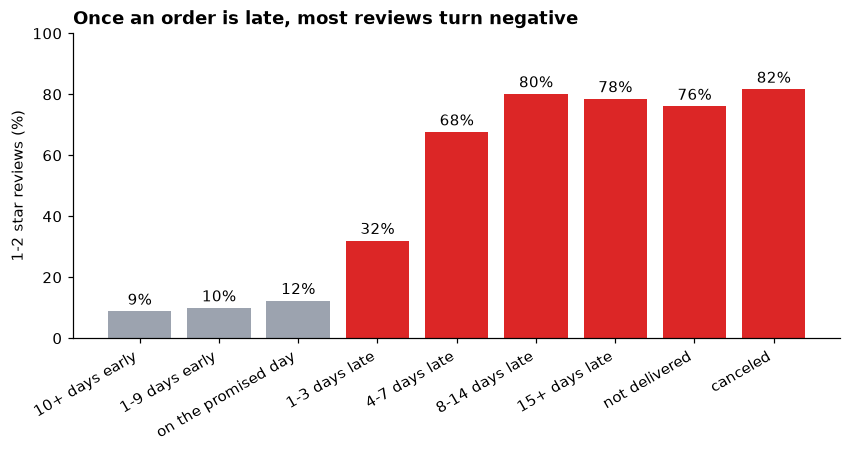

In [4]:
colors = [RED if ("late" in b or b in ("not delivered", "canceled")) else GREY for b in by_delay.delay_bucket]
fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.bar(by_delay.delay_bucket, by_delay.low_rating_pct, color=colors)
ax.bar_label(bars, fmt="%.0f%%", padding=2)
ax.set_title("Once an order is late, most reviews turn negative")
ax.set_ylabel("1-2 star reviews (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=30)
plt.setp(ax.get_xticklabels(), ha="right")
fig.savefig(FIGS / "rating_by_delay.png")
plt.show()

In [5]:
by_status = query(con, "03_low_ratings_by_delivery.sql").set_index("delivery_status")
by_status

,reviews,share_of_reviews_pct,low_ratings,share_of_low_ratings_pct,avg_rating
delivery_status,,,,,
on time,88952,90.7,8195,57.1,4.29
late,6344,6.5,3959,27.6,2.27
not delivered,1636,1.7,1244,8.7,1.81
canceled,1164,1.2,950,6.6,1.64


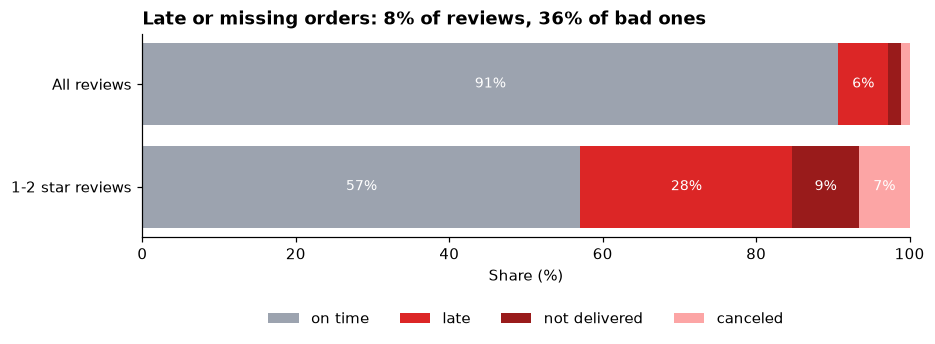

In [6]:
order = ["on time", "late", "not delivered", "canceled"]
seg_colors = {"on time": GREY, "late": RED, "not delivered": "#991b1b", "canceled": "#fca5a5"}
rows = {"All reviews": by_status.share_of_reviews_pct, "1-2 star reviews": by_status.share_of_low_ratings_pct}

fig, ax = plt.subplots(figsize=(9, 2.4))
for y, (label, shares) in enumerate(rows.items()):
    left = 0
    for status in order:
        width = shares[status]
        ax.barh(y, width, left=left, color=seg_colors[status], label=status if y == 0 else None)
        if width >= 4:
            ax.text(left + width / 2, y, f"{width:.0f}%", ha="center", va="center", color="white", fontsize=9)
        left += width
ax.set_yticks(range(len(rows)), rows.keys())
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share (%)")
ax.set_title("Late or missing orders: 8% of reviews, 36% of bad ones")
ax.legend(ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.3), frameon=False)
fig.savefig(FIGS / "low_ratings_by_delivery.png")
plt.show()

**Reading:** delivered orders were late 6.7% of the time. On-time orders average **4.29** stars, late ones **2.27**. Orders that arrived late or never arrived are 8% of all reviews but **36%** of the 1-2 star reviews, and canceled orders add another 7%.

Early deliveries don't earn extra credit: orders 10+ days early and orders 1-9 days early are rated almost the same. The drop starts at the first day late.

In [7]:
query(con, "04_late_by_state.sql").head(8)

,customer_state,delivered_orders,late_pct,median_delivery_days,avg_rating
0,MA,706,17.3,19.0,3.83
1,CE,1272,13.7,18.0,3.94
2,RJ,12129,11.9,12.0,3.97
3,BA,3210,11.9,17.0,3.93
4,PA,924,10.8,21.0,3.92
5,ES,1962,10.4,14.0,4.08
6,PB,509,10.2,18.0,4.07
7,MS,694,9.8,14.0,4.16


In [8]:
query(con, "05_late_by_category.sql")

,category,delivered_orders,late_pct,avg_rating_on_time,avg_rating_late
0,bed_bath_table,8990,7.3,4.15,2.24
1,health_beauty,8523,7.4,4.38,2.34
2,sports_leisure,7390,6.5,4.38,2.17
3,computers_accessories,6428,6.3,4.21,2.27
4,furniture_decor,6079,7.1,4.22,2.34
5,housewares,5630,5.3,4.31,2.26
6,watches_gifts,5426,7.3,4.27,2.21
7,telephony,4044,7.1,4.18,2.43
8,auto,3761,7.2,4.30,2.32
9,toys,3746,6.1,4.38,2.12


Late deliveries cluster in the north and northeast (MA, CE, BA, PA), far from São Paulo, where most sellers are. Product category barely matters: every large category is rated about 4.2-4.4 when on time and about 2.1-2.4 when late. **The delivery, not the product, drives the rating.**

## 3. What unhappy customers write about

Star ratings say *how* unhappy a customer is, not *why*. To find out why, I took a fixed random sample of **400 1-2 star reviews with text from each marketplace** and had Gemini (`gemini-3.5-flash-lite`, free tier) assign each one main complaint from 7 categories (`src/taxonomy.py`). The model returns structured JSON limited to those categories, and translates the Portuguese reviews.

400 reviews per marketplace gives a margin of error of about ±5 percentage points on each share.

In [9]:
mix = query(con, "06_issue_mix.sql")
table = (mix.pivot(index="primary_issue", columns="source", values="share_pct")
            .reindex(list(ISSUES)).fillna(0).rename(index=LABELS))
table[["olist", "amazon"]]

source,olist,amazon
primary_issue,,
Late delivery,40.0,0.3
Wrong or missing item,25.5,3.0
Damaged on arrival,4.3,6.8
Product quality,12.8,83.3
Seller service,14.8,0.5
Price / value,0.8,5.3
Other,2.0,1.0


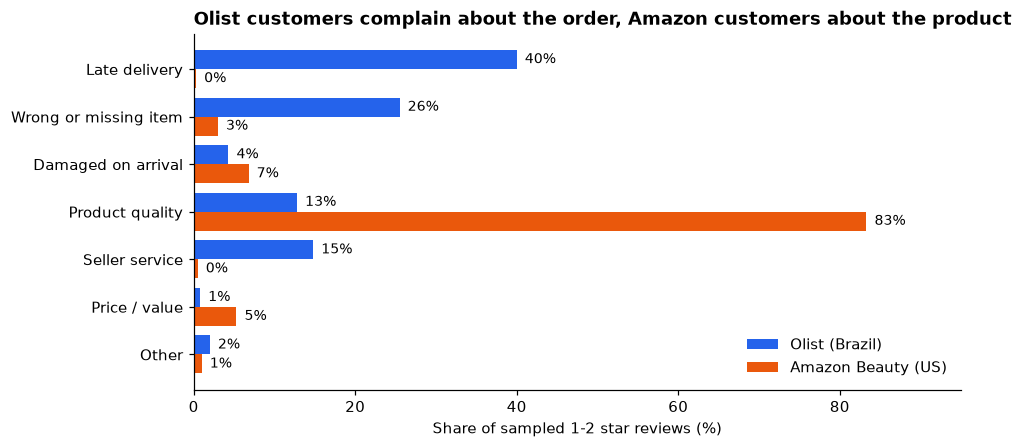

In [10]:
plot = table[["olist", "amazon"]].iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.2))
y = range(len(plot))
ax.barh([i + 0.2 for i in y], plot.olist, height=0.4, color=OLIST, label="Olist (Brazil)")
ax.barh([i - 0.2 for i in y], plot.amazon, height=0.4, color=AMAZON, label="Amazon Beauty (US)")
for i, (o, a) in enumerate(zip(plot.olist, plot.amazon)):
    ax.text(o + 1, i + 0.2, f"{o:.0f}%", va="center", fontsize=9)
    ax.text(a + 1, i - 0.2, f"{a:.0f}%", va="center", fontsize=9)
ax.set_yticks(list(y), plot.index)
ax.set_xlim(0, 95)
ax.set_xlabel("Share of sampled 1-2 star reviews (%)")
ax.set_title("Olist customers complain about the order, Amazon customers about the product")
ax.legend(frameon=False, loc="lower right")
fig.savefig(FIGS / "complaints_by_marketplace.png")
plt.show()

**Reading:** on Olist, **80%** of bad reviews are about getting the order (late delivery 40%, wrong or missing item 26%, seller service 15%). Only 13% are about the product itself. On Amazon Beauty it's the reverse: **83%** are about product quality and almost none mention delivery.

A marketplace of many small sellers, each shipping on their own, fails on logistics. Amazon's fulfillment network mostly removes that problem, so complaints shift to the product.

In [11]:
query(con, "07_olist_issue_by_delivery.sql")

,delivery,primary_issue,reviews,share_pct
0,late or not delivered,late_delivery,131,77.1
1,late or not delivered,seller_service,30,17.6
2,late or not delivered,wrong_or_missing_item,4,2.4
3,late or not delivered,other,3,1.8
4,late or not delivered,product_quality,1,0.6
5,late or not delivered,damaged_on_arrival,1,0.6
6,on time,wrong_or_missing_item,98,42.6
7,on time,product_quality,50,21.7
8,on time,late_delivery,29,12.6
9,on time,seller_service,29,12.6


When the order **was** on time, the top Olist complaint is a **wrong or missing item** (43%). That led to the next question.

## 4. A hidden problem: orders with several items

In [12]:
by_type = query(con, "09_order_type_ratings.sql")
by_type

,order_type,orders,avg_rating,low_rating_pct
0,one item,79969,4.36,7.5
1,"one seller, several items",7745,3.85,20.9
2,several sellers,1238,2.86,47.2


In [13]:
query(con, "10_missing_items_by_order_type.sql")

,order_type,low_ratings,wrong_or_missing_pct
0,one item,307,15.0
1,"one seller, several items",58,65.5
2,several sellers,21,85.7


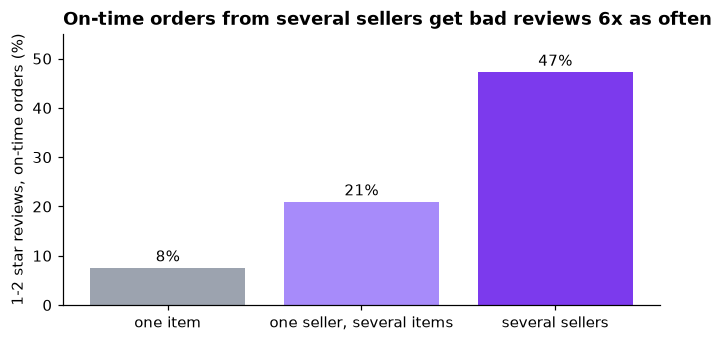

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.bar(by_type.order_type, by_type.low_rating_pct, color=[GREY, "#a78bfa", "#7c3aed"])
ax.bar_label(bars, fmt="%.0f%%", padding=2)
ax.set_title("On-time orders from several sellers get bad reviews 6x as often")
ax.set_ylabel("1-2 star reviews, on-time orders (%)")
ax.set_ylim(0, 55)
fig.savefig(FIGS / "order_type.png")
plt.show()

**Reading:** among orders delivered on time, one-item orders get 1-2 stars **7.5%** of the time. Orders with several items from one seller get them **21%** of the time, and orders from several sellers **47%**. In the labeled sample, most of those complaints are about a "missing" item: 66% for one seller with several items, 86% for several sellers.

A likely reason: each seller ships on its own, and Olist sends the review survey once the order is delivered or its estimated date passes. A customer can get that survey with only part of the order in hand. The data supports this but can't prove it. The several-seller group is also small (1,238 orders, 21 labeled reviews), so its exact share is rough, though the gap is large.

**What a marketplace could do:** tell customers at checkout and in the delivery message that the order arrives in several parcels, and ask for the review only after the last one arrives.

## 5. Can the LLM labels be trusted?

Two checks:
1. **Hand labels.** I labeled 100 of the sampled reviews myself (50 per marketplace) without looking at the model's answers (`src/hand_label.py`), then compared (`src/evaluate.py`).
2. **Delivery records (Olist).** When the model says a review is about late delivery, was the order actually late?

In [15]:
eval_path = LABELS_DIR / "evaluation.json"
evaluation = json.loads(eval_path.read_text()) if eval_path.exists() else None
if evaluation is None:
    print("Run src/hand_label.py and src/evaluate.py first.")
else:
    display(pd.DataFrame(evaluation["hand_labels"]["by_source"]).T)

,reviews,accuracy,kappa
both,91.0,0.648,0.511
amazon,44.0,0.614,0.197
olist,47.0,0.681,0.549


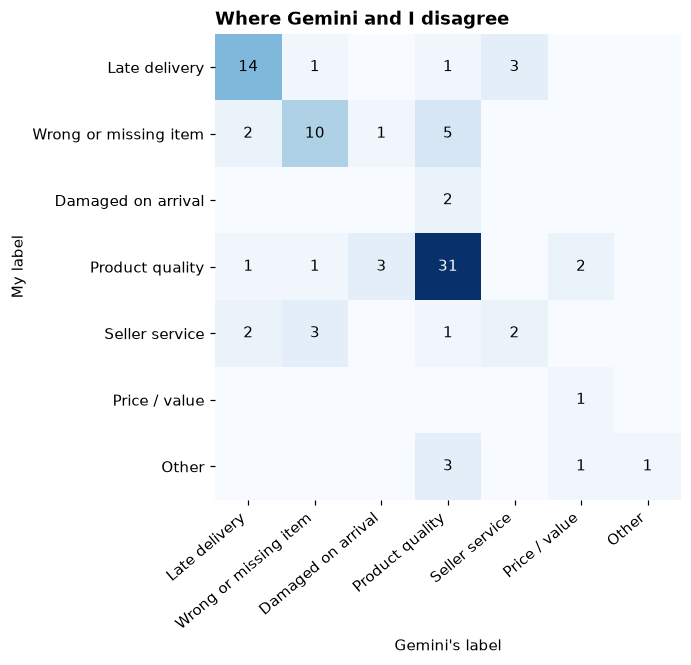

In [16]:
if evaluation:
    conf = pd.DataFrame(evaluation["hand_labels"]["confusion"])
    matrix = (conf.pivot_table(index="human", columns="llm", values="reviews", fill_value=0)
                  .reindex(index=list(ISSUES), columns=list(ISSUES), fill_value=0)
                  .astype(int))
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.imshow(matrix.values, cmap="Blues")
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            v = matrix.values[i, j]
            if v:
                ax.text(j, i, v, ha="center", va="center", color="white" if v > matrix.values.max() / 2 else "black")
    names = [LABELS[k] for k in ISSUES]
    ax.set_xticks(range(len(names)), names, rotation=40, ha="right")
    ax.set_yticks(range(len(names)), names)
    ax.set_xlabel("Gemini's label")
    ax.set_ylabel("My label")
    ax.set_title("Where Gemini and I disagree")
    ax.spines[:].set_visible(False)
    fig.savefig(FIGS / "confusion_matrix.png")
    plt.show()

In [17]:
records = query(con, "08_labels_vs_delivery_records.sql")
records

,llm_says_late_delivery,delivery_status,reviews
0,True,late,82
1,True,not delivered,33
2,True,on time,29
3,True,canceled,16
4,False,on time,201
5,False,late,17
6,False,canceled,13
7,False,not delivered,9


In [18]:
if evaluation and evaluation.get("delivery_records"):
    pd.Series(evaluation["delivery_records"])

In [19]:
if evaluation:
    shares = pd.DataFrame(evaluation["hand_labels"]["shares_same_reviews"])
    shares["issue"] = shares["issue"].map(LABELS)
    display(shares.rename(columns={"human": "hand labels", "llm": "Gemini"})
                  .sort_values(["source", "hand labels"], ascending=[False, False])
                  .set_index(["source", "issue"]))
    display(pd.Series(evaluation["hand_labels"]["adjudication"], name="blind review of disagreements"))

hand labels  Gemini
source issue                                     
olist  Late delivery                   18      19
       Wrong or missing item           13      15
       Product quality                  9       9
       Seller service                   7       4
amazon Product quality                 29      34
       Other                            5       1
       Wrong or missing item            5       0
       Damaged on arrival               2       4
       Late delivery                    1       0
       Price / value                    1       4
       Seller service                   1       1

settled                  32
disagreements            32
llm_fit_better           21
hand_label_fit_better    11
both_fit                  0
Name: blind review of disagreements, dtype: int64

**Reading**

- Gemini and I picked the same category for **59 of 91** reviews (65%, Cohen's kappa 0.51). Agreement was higher on Olist (68%, kappa 0.55) than on Amazon (61%). Amazon's kappa is only 0.20 because most of its reviews are "product quality": chance agreement is already high there, so the few other categories decide the score.
- I then reviewed the 32 disagreements **blind** (`src/review_disagreements.py`): each showed the two labels as A and B in random order. Gemini's label fit the definitions better in **21**, mine in **11**. Several of mine were slips, such as a nail polish review I had marked "late delivery". Against these reviewed labels, Gemini was right on **80 of 91 reviews (88%)**.
- Gemini's one systematic error: it calls products that broke *after use* "damaged on arrival".
- What matters most for the findings: the **category totals** on the same reviews match closely. On Olist, late delivery is 18 by hand vs 19 by Gemini, wrong or missing item 13 vs 15, product quality 9 vs 9. The conclusions rest on these shares, not on any single label.
- Against Olist's delivery records, **72%** of Gemini's "late delivery" labels were on orders that really were late or never arrived, and it labeled **82%** of the bad reviews on late or missing orders as late delivery. Most of its other "late" labels were on canceled orders (16) or on orders that met the promised date but took longer than the customer expected (29).

## 6. Conclusions

1. **Delivery is the biggest lever on Olist's ratings.** Late or missing orders are 8% of reviews and 36% of bad ones; a late order averages 2.3 stars against 4.3.
2. **Split shipments look like missing items.** On-time orders from several sellers get bad reviews 47% of the time against 7.5% for single items. Telling customers their order comes in several parcels is a cheap fix to test.
3. **The two marketplaces fail differently.** Olist's bad reviews are about getting the order (80%); Amazon Beauty's are about the product (83%).
4. **A free LLM did the labeling well enough to trust the totals:** 88% correct against blind-reviewed labels, category shares within a few reviews of the hand labels, and $0 spent.

**Limitations.** Olist and Amazon Beauty differ in more than logistics (country, product range, review culture), so the comparison is directional. The hand labels and the blind review come from one person, and for Portuguese reviews they relied on Gemini's own translation. The rating gaps are correlations: late orders also differ in region and product size.

**Next steps.** A second labeler; label all 10,497 Olist low ratings instead of a sample; test whether sellers with many late deliveries lose repeat customers.